# TerraSpectra — Week 1, step by step

**Our goal:** understand the real Kaggle pictures, prepare smaller spectral stacks, and understand how the map is built.

Imagine a picture made of 125 transparent pages. Each page measures a different slice of light. Our job is to organize those pages and make a useful summary. We are not training a disease model this week.

Run the cells from top to bottom. Choose the project `.venv` Python kernel in VS Code. Run the README preparation command once first. That command extracts the ZIP and creates the reports used here.

## 1. Find our project

A path is like an address for a file. This cell finds the project whether you opened the notebook from the repository or its notebooks folder. We import the same helper used by the preparation command, so the notebook and script follow the same rules.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import json
import csv
import numpy as np
import matplotlib.pyplot as plt
import rasterio
import joblib

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
assert (ROOT / "src/terraspectra").exists(), "Open this notebook inside the tspectra repository."
sys.path.insert(0, str(ROOT / "src"))
from terraspectra.prepare import read_cube
print("Project:", ROOT)


Project: /Users/sharath/Documents/ChatGPT/terraspectra/tspectra


## 2. Open our packing list

An inventory is a list of everything in a box. We have 600 labelled pictures and 300 without labels. The folder called `val` does not contain the correct class answers. Therefore, we hold aside 120 of the labelled pictures for development validation and use the other 480 to learn.

The extra 300 stay unlabelled. We must never guess their labels from filenames.

In [2]:
summary_path = ROOT / "reports/dataset_summary.json"
assert summary_path.exists(), "Run the README data preparation command first."
summary = json.loads(summary_path.read_text())
with (ROOT / "reports/inventory.csv").open() as handle:
    inventory = list(csv.DictReader(handle))
print("Files:", summary["files"])
print("Class counts:", summary["classes"])
print("Splits:", summary["splits"])
print("Original band counts:", summary["raw_band_counts"])
print("Binary extra bands removed:", summary["binary_extra_bands_removed"])


Files: 900
Class counts: {'Health': 200, 'Other': 200, 'Rust': 200, 'unlabelled': 300}
Splits: {'train': 480, 'validation': 120, 'unlabelled': 300}
Original band counts: {'125': 741, '126': 159}
Binary extra bands removed: 159


## 3. Inspect one picture before changing it

Rasterio opens TIFF files and reads their metadata. It returns `(bands, height, width)`. Our helper changes this to `(height, width, bands)`.

**A real cleaning discovery:** 159 files have a 126th plane containing only 0 and/or 65,535 (154 constant 65,535, three constant zero, two binary). The helper checks those values before dropping that last plane. We do not give it a guessed meaning. The remaining 125 bands become our input.

The CRS is described as unknown with unusual units. We cannot confidently put these patches onto a real farm map. A TIFF file can contain coordinate metadata without providing trustworthy farm locations.

In [3]:
example = next(row for row in inventory if row["split"] == "train" and row["label"] == "Health")
image_path = ROOT / "data/raw" / example["path"]
with rasterio.open(image_path) as image:
    print("Raw shape (bands, height, width):", (image.count, image.height, image.width))
    print("Stored numbers:", image.dtypes[0])
    print("Coordinate system:", image.crs)
    print("Transform:", image.transform)
cube = read_cube(image_path)
print("Clean shape (height, width, bands):", cube.shape)
print("Minimum and maximum sensor values:", float(cube.min()), float(cube.max()))


Raw shape (bands, height, width): (125, 64, 64)
Stored numbers: uint16
Coordinate system: 

GEOGCS["unknown",DATUM["unknown",SPHEROID["unretrievable - using WGS84",6378137,298.257223563]],PRIMEM["Greenwich",0],UNIT["metre",1],AXIS["Latitude",NORTH],AXIS["Longitude",EAST]]
Transform: | 0.00, 0.00, 5.79|
| 0.00,-0.00,-6.32|
| 0.00, 0.00, 1.00|


Clean shape (height, width, bands): (64, 64, 125)
Minimum and maximum sensor values: 157.0 4968.0


## 4. Make a picture we can see

Our screen has three colour channels. We choose three bands and stretch their brightness for display. This is an **illustrative three-band view**, not a calibrated natural-colour photo. The stretched values are only for the picture below; they do not replace the training measurements.

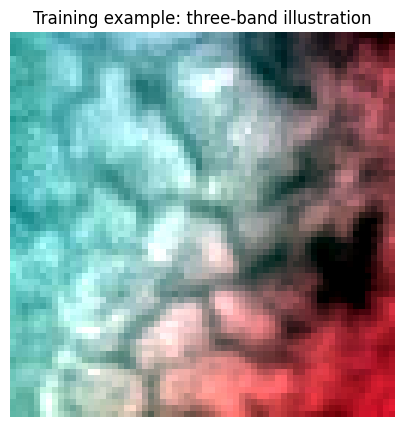

In [4]:
def display_three_channels(array):
    low = np.percentile(array, 2, axis=(0, 1), keepdims=True)
    high = np.percentile(array, 98, axis=(0, 1), keepdims=True)
    return np.clip((array - low) / np.maximum(high - low, 1e-6), 0, 1)

preview = display_three_channels(cube[:, :, [70, 40, 15]])
plt.figure(figsize=(5, 5))
plt.imshow(preview)
plt.title("Training example: three-band illustration")
plt.axis("off")
plt.show()


## 5. Look at a spectral curve

Choose one square in the picture. Its 125 values form a curve: the square changes brightness across the bands. There is no exact wavelength table in this ZIP, so we honestly label the horizontal axis with band numbers. The vertical axis shows stored sensor numbers, not a guaranteed physical reflectance measurement.

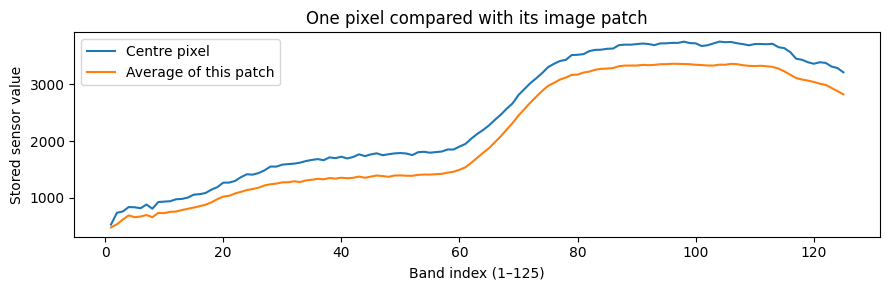

In [5]:
plt.figure(figsize=(9, 3))
plt.plot(np.arange(1, 126), cube[32, 32], label="Centre pixel")
plt.plot(np.arange(1, 126), cube.mean(axis=(0, 1)), label="Average of this patch")
plt.xlabel("Band index (1–125)")
plt.ylabel("Stored sensor value")
plt.title("One pixel compared with its image patch")
plt.legend()
plt.tight_layout()
plt.show()


## 6. Understand the scaler and PCA

Suppose one band uses bigger numbers than another. Scaling gives the bands comparable influence. Then PCA finds repeated patterns and makes 16 new summary pages. It mixes bands; it does not select 16 original wavelengths.

Only training pixels teach these steps. Validation is like a closed answer sheet: it must not teach the transformation. We sample 64 pixels per training picture to keep memory use small. The command saves the learned recipe so every later image gets the same treatment.

Read the short `prepare.py` functions alongside this cell: `extract_dataset`, `build_inventory`, `read_cube`, and `prepare`.

In [6]:
recipe = joblib.load(ROOT / "reports/preprocessing.joblib")
scaler = recipe["scaler"]
pca = recipe["pca"]
pixels = cube.reshape(-1, 125)
scaled_pixels = scaler.transform(pixels)
compressed = pca.transform(scaled_pixels).reshape(64, 64, -1).astype("float32")
print("Original cube:", cube.shape)
print("PCA cube:", compressed.shape)
print("Sampled training pixels:", summary["training_pixels_sampled"])
print("Retained variation:", f"{summary['retained_variance']:.2%}")
print("This percentage is NOT disease accuracy.")
saved = np.load(ROOT / "data/processed" / example["processed_path"])
np.testing.assert_allclose(compressed, saved, rtol=1e-5, atol=1e-5)
print("The notebook transformation matches the saved array.")


Original cube: (64, 64, 125)
PCA cube: (64, 64, 16)
Sampled training pixels: 30720
Retained variation: 99.92%
This percentage is NOT disease accuracy.
The notebook transformation matches the saved array.


## 7. See what the summary pages keep

The first plot shows how quickly the components collect variation. The second uses three PCA components as screen colours. Different colours show spectral patterns; they do not automatically mean healthy or diseased tissue.

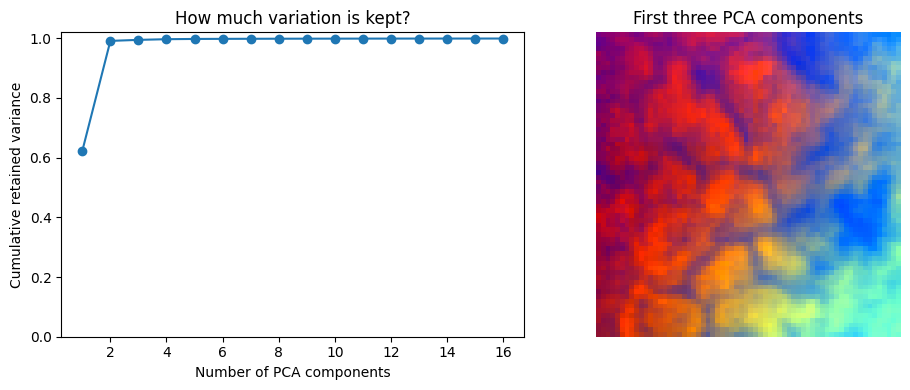

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(np.arange(1, pca.n_components_ + 1), np.cumsum(pca.explained_variance_ratio_), marker="o")
axes[0].set(xlabel="Number of PCA components", ylabel="Cumulative retained variance", ylim=(0, 1.02), title="How much variation is kept?")
axes[1].imshow(display_three_channels(compressed[:, :, :3]))
axes[1].set_title("First three PCA components")
axes[1].axis("off")
plt.tight_layout()
plt.savefig(ROOT / "reports/pca_preview.png", dpi=140, bbox_inches="tight")
plt.show()


## 8. Optional: the plan's 200+ band mock-cube exercise

The real dataset has 125 useful bands. We do not invent extra bands for training. Instead, this separate exercise creates a **synthetic 224-band GeoTIFF**. Its random values and coordinates are deliberately invented. This only demonstrates a file format and array shape.

We can practise PCA on it, but the result has no crop-health meaning and never enters the real data pipeline.

In [8]:
from terraspectra.make_mock_cube import make_mock_cube
from sklearn.decomposition import PCA
mock_path = make_mock_cube()
with rasterio.open(mock_path) as image:
    mock = image.read()
    print("Synthetic shape:", mock.shape, "Synthetic CRS:", image.crs)
mock_pixels = np.moveaxis(mock, 0, -1).reshape(-1, 224)
mock_pca = PCA(n_components=16, random_state=42, svd_solver="randomized")
mock_small = mock_pca.fit_transform(mock_pixels)
print("Synthetic PCA shape:", mock_small.reshape(32, 32, 16).shape)


/Users/sharath/Documents/ChatGPT/terraspectra/tspectra/data/raw_mock/synthetic_224_band.tif
Synthetic shape: (224, 32, 32) Synthetic CRS: EPSG:4326


Synthetic PCA shape: (32, 32, 16)


## 9. How the map fits into this week

Think of **React** as the frame, **Mapbox** as the map paper, and **Deck.gl** as a transparent sheet holding a farm outline. `MapboxOverlay` keeps the transparent sheet aligned as you move the map.

Open these files:

- `frontend/src/farm.ts`: an invented farm boundary near Bengaluru; GeoJSON uses `[longitude, latitude]`.
- `frontend/src/FarmMap.tsx`: creates the map, overlay and controls; removes them on cleanup.
- `frontend/src/App.tsx`: dashboard layout and real preparation counts.

The boundary is a demonstration. It does not locate the Kaggle image patches. Without your public Mapbox token, the app displays a setup placeholder. Follow the README to add the token and start the map.

**Try it:** pan, zoom, rotate, tilt, toggle the boundary, and press Reset view. The outline should remain aligned with the map. No disease heatmap belongs in Week 1.

## 10. What we can honestly say

We have prepared a small, reproducible data pipeline and a map scaffold. We have not established disease accuracy, chemical deficiencies, geographic farm risk, or a three-week warning period.

A random patch split can contain neighbouring patches from one original scene. The ZIP does not identify their source scenes or dates reliably. This validation split is suitable for development, not proof of generalization to unseen farms.

**Next week:** build a compact classifier using the class labels in the inventory. Keep validation separate and compare a simple baseline before adding a transformer.

Read `docs/WEEK_1_GUIDE.md` for the full explanation and `docs/VALIDATION.md` for checks actually completed.

Sources: [Kaggle competition](https://www.kaggle.com/competitions/beyond-visible-spectrum-ai-for-agriculture-P1/data), [Rasterio reading](https://rasterio.readthedocs.io/en/stable/topics/reading.html), [PCA documentation](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html), [MapboxOverlay](https://deck.gl/docs/api-reference/mapbox/mapbox-overlay).